# CONCH · Kimi R1 · Effective acquisition magnification

Run all cells in order. All analysis code is in the notebook. Use Python3.11, the official CONCH library at141cc09c7d4ff33d8eda562bd75169b457f71a62, torch2.5.0, torchvision0.20.0, NumPy1.26.4, pandas2.2.2, sklearn1.5.2, Pillow10.4.0, pyarrow16.1.0 and scikit-image0.24.0.

## 1. Data source / acquisition

Download CRC-VAL-HE-7K and the non-normalized NCT-CRC-HE-100K image shards from the pinned public dataset revision. The latter supplies the fixed reference-training panel. Official CONCH and ImageNet weights are acquired in section4.

**Environment setup before starting the kernel (Linux, Python 3.11):**

Create this shared GPT/Kimi environment before opening the notebook. Keep it separate from the primary CONCH environment, which uses different numerical-library versions.

```bash
python3.11 -m venv .venv-conch-shared
.venv-conch-shared/bin/python -m pip install torch==2.5.0 torchvision==0.20.0 --index-url https://download.pytorch.org/whl/cu124
.venv-conch-shared/bin/python -m pip install numpy==1.26.4 scipy==1.13.1 pandas==2.2.2 scikit-learn==1.5.2 Pillow==10.4.0 pyarrow==16.1.0 scikit-image==0.24.0 statsmodels==0.14.2 opencv-python-headless==4.10.0.84
.venv-conch-shared/bin/python -m pip install matplotlib==3.9.4 timm==0.9.16 transformers==4.40.1 tokenizers==0.19.1 huggingface-hub==0.23.5 ftfy==6.3.1 h5py==3.11.0 open-clip-torch==2.24.0 requests==2.34.2 regex==2026.11.9 safetensors==0.8.0 nbformat==5.10.4 nbclient==0.10.4 nbconvert==7.16.6 ipykernel==6.29.5
.venv-conch-shared/bin/python -m pip install --no-deps "git+https://github.com/mahmoodlab/CONCH.git@141cc09c7d4ff33d8eda562bd75169b457f71a62"
.venv-conch-shared/bin/python -m ipykernel install --user --name conch-gpt-kimi-inline --display-name "CONCH GPT/Kimi"
```

Select **CONCH GPT/Kimi** before Run All. The CUDA 12.4 wheels require a compatible NVIDIA driver; the code also selects CPU if CUDA is unavailable. Authenticate with Hugging Face using an account that can access `MahmoodLab/conch` before the checkpoint-download cell. The `huggingface-cli login` command is provided by the pinned Hub package.

The default input directory is `inputs/` below the notebook working directory. Set `CONCH_INPUTS` before starting the kernel to reuse a shared raw-input directory. The notebook verifies its declared downloaded inputs and runs the calculations shown below, including the stated scoring or eligibility diagnostic. All analysis-specific functions are inline; the installed CONCH package is the pinned public model implementation.

The CONCH model-input transform is explicitly set to 224×224 in the scoring cell. Reference-network weights and transforms are specified in that same cell.


In [1]:
AXIS=1
CRC_SHARDS=['data/CRC_VAL_HE_7K-00000-of-00003-cce1097526b69125.parquet',
 'data/CRC_VAL_HE_7K-00001-of-00003-fbb5de8b1164f4ea.parquet',
 'data/CRC_VAL_HE_7K-00002-of-00003-2009e87e0c48fccf.parquet']

from pathlib import Path
import concurrent.futures,hashlib,io,json,os,shutil,time,zipfile
import requests
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from PIL import Image as PILImage
import matplotlib.pyplot as plt
from IPython.display import display,Markdown,Image
from huggingface_hub import hf_hub_download,hf_hub_url,get_hf_file_metadata
from sklearn.neighbors import NearestNeighbors,NearestCentroid
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

INPUT=Path(os.environ.get('CONCH_INPUTS',Path.cwd()/'inputs'));INPUT.mkdir(parents=True,exist_ok=True)
OUT=Path.cwd()/f'conch-kimi-r1-test-{AXIS:02}-outputs';OUT.mkdir(exist_ok=True)
CLASSES=['ADI','BACK','DEB','LYM','MUC','MUS','NORM','STR','TUM']
CLASS_MAP={'ADI':'ADI','BACK':'BACK','DEB':'DEB','LYM':'LYM','MUC':'MUC','MUS':'MUS','NORM':'NORM','STR':'STR','TUM':'TUM','NCS':'DEB','NOR':'NORM','FCT':'STR','BLD':None}
REVISION='97765ecb14bf11ce7bb8779a1097d187844a67cb'
SOURCE_REVISION='141cc09c7d4ff33d8eda562bd75169b457f71a62'
CHECKPOINT_REVISION='f9ca9f877171a28ade80228fb195ac5d79003357'
SEED=20260715

def sha256(path):
    digest=hashlib.sha256()
    with open(path,'rb') as source:
        for block in iter(lambda:source.read(8<<20),b''):digest.update(block)
    return digest.hexdigest()

def show_figure(figure):
    output=io.BytesIO();figure.savefig(output,format='png',dpi=130,bbox_inches='tight')
    display(Image(data=output.getvalue()));plt.close(figure)

def download(url,destination,expected_sha256=None,expected_bytes=None):
    destination=Path(destination);destination.parent.mkdir(parents=True,exist_ok=True)
    if destination.is_file() and (expected_bytes is None or destination.stat().st_size==expected_bytes) and (expected_sha256 is None or sha256(destination)==expected_sha256):return destination
    temporary=destination.with_name(destination.name+f'.{os.getpid()}.part')
    with requests.get(url,stream=True,timeout=120) as response:
        response.raise_for_status()
        with open(temporary,'wb') as target:
            for block in response.iter_content(8<<20):target.write(block)
    if expected_bytes is not None:assert temporary.stat().st_size==expected_bytes
    if expected_sha256 is not None:assert sha256(temporary)==expected_sha256
    temporary.replace(destination);return destination

def pinned_parquet(filename):
    url=hf_hub_url('1aurent/NCT-CRC-HE',filename,repo_type='dataset',revision=REVISION)
    metadata=get_hf_file_metadata(url)
    digest=metadata.etag.strip('"')
    assert len(digest)==64,'Expected a large-file SHA-256 identity'
    return download(url,INPUT/'hf_parquet'/filename,digest,metadata.size)


with concurrent.futures.ThreadPoolExecutor(max_workers=3) as pool:crc_paths=list(pool.map(pinned_parquet,CRC_SHARDS))
display(pd.DataFrame([dict(source='CRC-VAL',url=hf_hub_url('1aurent/NCT-CRC-HE',name,repo_type='dataset',revision=REVISION),sha256=sha256(path)) for name,path in zip(CRC_SHARDS,crc_paths)]))

from huggingface_hub import list_repo_files
nct_filenames=sorted(name for name in list_repo_files('1aurent/NCT-CRC-HE',repo_type='dataset',revision=REVISION) if name.startswith('data/NCT_CRC_HE_100K_NONORM-') and name.endswith('.parquet'))
assert len(nct_filenames)==31
with concurrent.futures.ThreadPoolExecutor(max_workers=4) as pool:nct_paths=list(pool.map(pinned_parquet,nct_filenames))


/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,source,url,sha256
0,CRC-VAL,https://huggingface.co/datasets/1aurent/NCT-CR...,fc4aa78c380802f27e59a70b2f2877dc3d2b82ddc2b800...
1,CRC-VAL,https://huggingface.co/datasets/1aurent/NCT-CR...,d607ebd6b861e3aec2ae2d457993f42222393abb9bdd99...
2,CRC-VAL,https://huggingface.co/datasets/1aurent/NCT-CR...,d733e143f0c984d24262d7b98d30669a885e7a6e3fcb46...


## 2. Data processing

Decode RGB images, deduplicate CRC by exact pixel content, and select the first3,200 filenames per training class before the seed0 sample of2,778/class. Deduplicate the selected reference by pixels and display overlap diagnostics.

In [2]:
def save_image(raw,source,source_key,label):
    encoded_hash=hashlib.sha256(raw).hexdigest()
    path=INPUT/'raw_images'/source/(encoded_hash+'.image')
    path.parent.mkdir(parents=True,exist_ok=True)
    if not path.exists() or sha256(path)!=encoded_hash:
        temporary=path.with_name(path.name+f'.{os.getpid()}.part');temporary.write_bytes(raw);temporary.replace(path)
    return dict(cohort=source,source_key=source_key,tile_id=encoded_hash,path=str(path),raw_label=label,encoded_sha256=encoded_hash)

crc_rows=[]
for source_name,path in zip(CRC_SHARDS,crc_paths):
    parquet=pq.ParquetFile(path)
    for group in range(parquet.num_row_groups):
        for index,example in enumerate(parquet.read_row_group(group,columns=['image','label']).to_pylist()):
            image=example['image'];label=CLASSES[int(example['label'])]
            source_key=f'{source_name}:{group}:{index}:{image.get("path","")}'
            crc_rows.append(save_image(image['bytes'],'CRC',source_key,label))

crc=pd.DataFrame(crc_rows)
crc['label']=crc.raw_label.map({name:index for index,name in enumerate(CLASSES)})
crc['file']=[row.source_key.rsplit(':',1)[-1] for row in crc.itertuples(index=False)]

nct_rows=[]
for filename,path in zip(nct_filenames,nct_paths):
    parquet=pq.ParquetFile(path)
    for group in range(parquet.num_row_groups):
        for index,example in enumerate(parquet.read_row_group(group,columns=['image','label']).to_pylist()):
            label=CLASSES[int(example['label'])];image=example['image'];key=Path(image.get('path') or f'{group}-{index}').name
            nct_rows.append(dict(source_file=filename,row_group=group,row_index=index,raw_label=label,file=key,image=image))
inventory=pd.DataFrame(nct_rows);selected=[]
for label in CLASSES:
    group=inventory[inventory.raw_label==label].sort_values('file').head(3200)
    for record in group.sample(n=min(2778,len(group)),random_state=0).itertuples(index=False):
        row=save_image(record.image['bytes'],'NCT-NONORM',f'{record.source_file}:{record.row_group}:{record.row_index}:{record.file}',label)
        row['label']=CLASSES.index(label);selected.append(row)
train=pd.DataFrame(selected)
def pixel_hash(path):
    with PILImage.open(path) as image:return hashlib.sha256(np.asarray(image.convert('RGB')).tobytes()).hexdigest()
for frame in [crc,train]:frame['pixel_sha256']=[pixel_hash(path) for path in frame.path]
test=crc.drop_duplicates('pixel_sha256').reset_index(drop=True)
train=train.drop_duplicates('pixel_sha256').reset_index(drop=True)
print('CRC duplicate exclusions:',len(crc)-len(test))
print('Training subset:',len(train),'exact pixel overlap:',len(set(train.pixel_sha256)&set(test.pixel_sha256)))
train.to_csv(OUT/'reference_training_images.csv',index=False);test.to_csv(OUT/'evaluation_images.csv',index=False)
display(train.groupby('raw_label').size().rename('Reference images'))
del nct_rows,inventory


CRC duplicate exclusions: 0
Training subset: 25002 exact pixel overlap: 0


raw_label
ADI     2778
BACK    2778
DEB     2778
LYM     2778
MUC     2778
MUS     2778
NORM    2778
STR     2778
TUM     2778
Name: Reference images, dtype: int64

## 3. Axis definition and level construction

Use factors1,2,4,8,16. Each level bicubically downsamples then restores the image size, retaining tissue identity and field of view. Starting from the dataset’s0.5μm/pixel convention, the effective resolution is0.5times the factor. The same tiles appear at every level.

In [3]:
LEVELS=[1,2,4,8,16]
def degrade(image,factor):
    if factor==1:return image.copy()
    width,height=image.size
    small=image.resize((width//factor,height//factor),PILImage.Resampling.BICUBIC)
    return small.resize((width,height),PILImage.Resampling.BICUBIC)
display(pd.DataFrame({'factor':LEVELS,'effective_microns_per_pixel':[.5*factor for factor in LEVELS],'size_after_downsample':[224//factor for factor in LEVELS]}))


,factor,effective_microns_per_pixel,size_after_downsample
0,1,0.5,224
1,2,1.0,112
2,4,2.0,56
3,8,4.0,28
4,16,8.0,14


## 4. Model results or released scores

Run CONCH zero-shot at every level with the official CRC prompt ensemble and224-pixel model input. No CONCH fine-tuning occurs. The reference is frozen ImageNet ResNet50 with20-nearest-neighbor voting. Its primary neighbor bank is the native training subset; a second condition rebuilds that bank from the same training images at each level.

In [4]:
import torch
import torchvision.models as models
from torchvision import transforms
from conch.open_clip_custom import create_model_from_pretrained
from conch.downstream.zeroshot_path import zero_shot_classifier
torch.set_num_threads(4)
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
checkpoint=INPUT/'conch_checkpoint/pytorch_model.bin'
if not checkpoint.exists() or sha256(checkpoint)!='40a9644b9ba0e83a74576e0a5e5f7313599fa9c9cdaf3c20f8a3e271b0e9ae7c':
    checkpoint=Path(hf_hub_download('MahmoodLab/conch','pytorch_model.bin',revision=CHECKPOINT_REVISION))
assert sha256(checkpoint)=='40a9644b9ba0e83a74576e0a5e5f7313599fa9c9cdaf3c20f8a3e271b0e9ae7c'
prompt_path=download(f'https://raw.githubusercontent.com/mahmoodlab/CONCH/{SOURCE_REVISION}/prompts/crc100k_prompts_all_per_class.json',INPUT/'crc100k_prompts_all_per_class.json','5cac7ab39a593e10d053647842401eae00b94351bd33c5edcad29b17757343e2')
prompt=json.loads(prompt_path.read_text())['0']
conch,preprocess=create_model_from_pretrained('conch_ViT-B-16',str(checkpoint),device=DEVICE,force_image_size=224)
conch.eval()
text_weights=zero_shot_classifier(conch,[prompt['classnames'][name] for name in CLASSES],prompt['templates'],device=DEVICE)

@torch.inference_mode()
def image_embeddings(frame,model,preprocess,is_conch=False):
    values=[]
    for start in range(0,len(frame),64):
        batch=[]
        for path in frame.path.iloc[start:start+64]:
            with PILImage.open(path) as image:batch.append(preprocess(image.convert('RGB')))
        tensor=torch.stack(batch).to(DEVICE)
        encoded=model.encode_image(tensor,proj_contrast=True,normalize=True) if is_conch else model(tensor)
        values.append(encoded.cpu().numpy())
    return np.concatenate(values)


reference_weight=models.ResNet50_Weights.IMAGENET1K_V1
weight=download(reference_weight.url,INPUT/Path(reference_weight.url).name)
assert sha256(weight).startswith(Path(reference_weight.url).stem.split('-')[-1])
resnet=models.resnet50(weights=None);resnet.load_state_dict(torch.load(weight,map_location='cpu',weights_only=True));resnet.fc=torch.nn.Identity();resnet=resnet.to(DEVICE).eval()
pre_resnet=transforms.Compose([transforms.ToTensor(),transforms.Normalize(mean=[.485,.456,.406],std=[.229,.224,.225])])

@torch.inference_mode()
def extract_features(frame,factor,model,preprocess,is_conch=False):
    features=[]
    for start in range(0,len(frame),64):
        images=[]
        for path in frame.path.iloc[start:start+64]:
            with PILImage.open(path) as image:images.append(preprocess(degrade(image.convert('RGB'),factor)))
        batch=torch.stack(images).to(DEVICE)
        encoded=model.encode_image(batch,proj_contrast=True,normalize=True) if is_conch else model(batch)
        encoded=torch.nn.functional.normalize(encoded,dim=1)
        features.append(encoded.cpu().numpy())
    return np.concatenate(features)

def knn_predict(train_features,labels,test_features,k=20):
    result=[]
    for start in range(0,len(test_features),256):
        similarity=test_features[start:start+256]@train_features.T
        neighbors=np.argpartition(-similarity,k,axis=1)[:,:k]
        for indices in neighbors:
            values,counts=np.unique(labels[indices],return_counts=True)
            result.append(values[counts.argmax()])
    return np.asarray(result)

native_reference=extract_features(train,1,resnet,pre_resnet)
labels=train.label.to_numpy();rows=[]
for factor in LEVELS:
    target_features=extract_features(test,factor,resnet,pre_resnet)
    adapted_reference=native_reference if factor==1 else extract_features(train,factor,resnet,pre_resnet)
    for name,reference in [('ResNet50 kNN fixed',native_reference),('ResNet50 kNN refit',adapted_reference)]:
        predicted=knn_predict(reference,labels,target_features)
        for tile,true,prediction in zip(test.tile_id,test.label,predicted):rows.append(dict(cohort='CRC validation',tile_id=tile,label=int(true),method=name,level=factor,prediction=int(prediction)))
    conch_features=extract_features(test,factor,conch,preprocess,True)
    logits=float(conch.logit_scale.exp().detach().cpu())*conch_features@text_weights.detach().cpu().numpy()
    np.save(OUT/f'conch_logits_factor{factor}.npy',logits)
    for tile,true,prediction in zip(test.tile_id,test.label,logits.argmax(axis=1)):rows.append(dict(cohort='CRC validation',tile_id=tile,label=int(true),method='CONCH',level=factor,prediction=int(prediction)))
    print('Completed factor',factor,flush=True)
predictions=pd.DataFrame(rows);predictions.to_csv(OUT/'per_image_predictions.csv.gz',index=False)


/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv/lib/python3.11/site-packages/conch/open_clip_custom/factory.py:18: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental featur

Completed factor 1


Completed factor 2


Completed factor 4


Completed factor 8


Completed factor 16


## 5. Curves and controls

Calculate paired class-stratified tile-bootstrap intervals, balanced accuracy and class-specific recalls. Compare the frozen and per-level-refitted references. SSIM on the first300 evaluation images checks that the transformation changes image detail in the intended order.

In [5]:
from skimage.metrics import structural_similarity
axis_order=[]
for factor in LEVELS:
    scores=[]
    for path in test.path.iloc[:300]:
        with PILImage.open(path) as image:native=image.convert('RGB')
        changed=degrade(native,factor)
        scores.append(structural_similarity(np.asarray(native),np.asarray(changed),channel_axis=2,data_range=255))
    axis_order.append(dict(factor=factor,mean_ssim=float(np.mean(scores))))
axis_order=pd.DataFrame(axis_order);display(axis_order);axis_order.to_csv(OUT/'axis_order.csv',index=False)


,factor,mean_ssim
0,1,1.000000
1,2,0.858922
2,4,0.564377
3,8,0.293984
4,16,0.210428


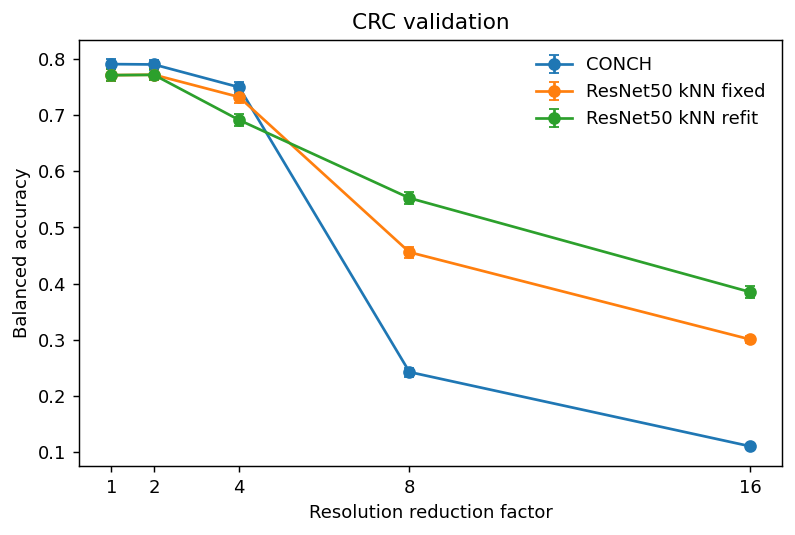

,cohort,method,level,balanced_accuracy,low,high,n_images
0,CRC validation,CONCH,1,0.790848,0.781414,0.799861,7180
1,CRC validation,CONCH,2,0.790222,0.781195,0.798856,7180
2,CRC validation,CONCH,4,0.749759,0.739638,0.759693,7180
3,CRC validation,CONCH,8,0.242689,0.234636,0.250251,7180
4,CRC validation,CONCH,16,0.110560,0.109690,0.111347,7180
5,CRC validation,ResNet50 kNN fixed,1,0.771179,0.760292,0.781446,7180
6,CRC validation,ResNet50 kNN fixed,2,0.771936,0.761732,0.781838,7180
7,CRC validation,ResNet50 kNN fixed,4,0.732286,0.721146,0.742466,7180
8,CRC validation,ResNet50 kNN fixed,8,0.455990,0.446001,0.465822,7180
9,CRC validation,ResNet50 kNN fixed,16,0.300765,0.294785,0.306573,7180


,cohort,method,drop,low,high
0,CRC validation,CONCH,0.680288,0.671434,0.688938
1,CRC validation,ResNet50 kNN fixed,0.470414,0.459452,0.482107
2,CRC validation,ResNet50 kNN refit,0.386083,0.373021,0.399043


level                                          1         2         4   \
cohort         method             label                                 
CRC validation CONCH              ADI    0.971599  0.973094  0.943946   
                                  BACK   0.455726  0.453365  0.819362   
                                  DEB    0.914454  0.920354  0.820059   
                                  LYM    0.995268  1.000000  0.968454   
                                  MUC    0.983575  0.982609  0.936232   
                                  MUS    0.932432  0.893581  0.785473   
                                  NORM   0.780027  0.663968  0.507422   
                                  STR    0.425178  0.484561  0.327791   
                                  TUM    0.659367  0.740470  0.639092   
               ResNet50 kNN fixed ADI    0.991779  0.994021  0.990284   
                                  BACK   0.774498  0.665880  0.667060   
                                  DEB    0.808260  0.902655  0.846608   
                                  LYM    0.785489  0.900631  0.858044   
                                  MUC    0.689855  0.691787  0.763285   
                                  MUS    0.589527  0.609797  0.457770   
                                  NORM   0.925776  0.901484  0.909582   
                                  STR    0.603325  0.577197  0.608076   
                                  TUM    0.772101  0.703974  0.489862   
               ResNet50 kNN refit ADI    0.991779  0.990284  0.970105   
                                  BACK   0.774498  0.504132  0.353011   
                                  DEB    0.808260  0.946903  0.775811   
                                  LYM    0.785489  0.858044  0.660883   
                                  MUC    0.689855  0.798068  0.787440   
                                  MUS    0.589527  0.614865  0.570946   
                                  NORM   0.925776  0.932524  0.919028   
                                  STR    0.603325  0.532067  0.380048   
                                  TUM    0.772101  0.768856  0.805353   

level                                          8         16  
cohort         method             label                      
CRC validation CONCH              ADI    0.440957  0.004484  
                                  BACK   0.845336  0.990555  
                                  DEB    0.000000  0.000000  
                                  LYM    0.454259  0.000000  
                                  MUC    0.033816  0.000000  
                                  MUS    0.177365  0.000000  
                                  NORM   0.017544  0.000000  
                                  STR    0.033254  0.000000  
                                  TUM    0.181671  0.000000  
               ResNet50 kNN fixed ADI    0.981315  0.809417  
                                  BACK   0.644628  0.397875  
                                  DEB    0.138643  0.000000  
                                  LYM    0.086751  0.000000  
                                  MUC    0.919807  0.982609  
                                  MUS    0.168919  0.000000  
                                  NORM   0.438596  0.110661  
                                  STR    0.225653  0.000000  
                                  TUM    0.499594  0.406326  
               ResNet50 kNN refit ADI    0.943946  0.847534  
                                  BACK   0.114522  0.024793  
                                  DEB    0.469027  0.230088  
                                  LYM    0.334385  0.050473  
                                  MUC    0.629952  0.355556  
                                  MUS    0.606419  0.462838  
                                  NORM   0.869096  0.704453  
                                  STR    0.194774  0.125891  
                                  TUM    0.809408  0.664234

In [6]:
def class_bootstrap(frame,rng,repeats=2000):
    result=np.zeros(repeats)
    for _,group in frame.groupby('label'):
        correct=(group.prediction==group.label).to_numpy(dtype=float)
        for start in range(0,repeats,100):
            stop=min(start+100,repeats);sample=rng.integers(0,len(correct),(stop-start,len(correct)))
            result[start:stop]+=correct[sample].mean(axis=1)
    return result/frame.label.nunique()
random=np.random.default_rng(20260722);curve_rows=[];effect_rows=[];within_rows=[]
for (cohort,method),frame in predictions.groupby(['cohort','method']):
    for level,group in frame.groupby('level'):
        recalls=group.assign(correct=(group.prediction==group.label).astype(float)).groupby('label').correct.mean()
        bootstrap=class_bootstrap(group,random);low,high=np.quantile(bootstrap,[.025,.975])
        curve_rows.append(dict(cohort=cohort,method=method,level=level,balanced_accuracy=recalls.mean(),low=low,high=high,n_images=len(group)))
        for label,recall in recalls.items():within_rows.append(dict(cohort=cohort,method=method,level=level,label=CLASSES[label],recall=recall))
    if len(LEVELS)>1:
        wide=frame.pivot(index=['tile_id','label'],columns='level',values='prediction')
        differences=((wide[min(LEVELS)].to_numpy()==wide.index.get_level_values('label')).astype(float)-(wide[max(LEVELS)].to_numpy()==wide.index.get_level_values('label')).astype(float))
        paired=pd.DataFrame({'label':wide.index.get_level_values('label'),'difference':differences})
        boot=np.zeros(2000)
        for _,group in paired.groupby('label'):
            values=group.difference.to_numpy()
            for start in range(0,2000,100):boot[start:start+100]+=values[random.integers(0,len(values),(100,len(values)))].mean(axis=1)
        boot/=paired.label.nunique();low,high=np.quantile(boot,[.025,.975])
        effect_rows.append(dict(cohort=cohort,method=method,drop=paired.groupby('label').difference.mean().mean(),low=low,high=high))
curves=pd.DataFrame(curve_rows);effects=pd.DataFrame(effect_rows);within=pd.DataFrame(within_rows)
curves.to_csv(OUT/'curves.csv',index=False);effects.to_csv(OUT/'paired_effects.csv',index=False);within.to_csv(OUT/'within_class.csv',index=False)
fig,axes=plt.subplots(1,curves.cohort.nunique(),figsize=(6*curves.cohort.nunique(),4),squeeze=False,constrained_layout=True)
for ax,(cohort,frame) in zip(axes.ravel(),curves.groupby('cohort')):
    for method,group in frame.groupby('method'):
        ax.errorbar(group.level,group.balanced_accuracy,yerr=[group.balanced_accuracy-group.low,group.high-group.balanced_accuracy],marker='o',capsize=3,label=method)
    ax.set(title=cohort,xlabel='HED perturbation strength' if AXIS==2 else 'Resolution reduction factor',ylabel='Balanced accuracy',xticks=LEVELS);ax.legend(frameon=False)
show_figure(fig);display(curves);display(effects)
display(within.pivot(index=['cohort','method','label'],columns='level',values='recall'))
if AXIS==3:
    fig,ax=plt.subplots(figsize=(7,4),constrained_layout=True)
    table=curves.pivot(index='cohort',columns='method',values='balanced_accuracy');table.plot.bar(ax=ax)
    ax.set(ylabel='Native-resolution balanced accuracy',xlabel='Evaluation cohort');show_figure(fig)


## 6. Decision and reason

In [7]:
conch_effect=effects[effects.method=='CONCH'].iloc[0]
fixed=effects[effects.method=='ResNet50 kNN fixed'].iloc[0]
refit=effects[effects.method=='ResNet50 kNN refit'].iloc[0]
decision='Accept effective-resolution sensitivity' if conch_effect.low>0 else 'Reject a supported effective-resolution effect under the paired-interval criterion'
display(Markdown(f'**{decision}.** The paired native-minus-most-degraded CONCH drop is {100*conch_effect["drop"]:.2f} percentage points (95% interval {100*conch_effect.low:.2f} to {100*conch_effect.high:.2f}). The frozen ResNet50 reference drops {100*fixed["drop"]:.2f} points; refitting its neighbor bank at each level gives {100*refit["drop"]:.2f}.'))
display(Markdown('This is a controlled change in effective resolution. It characterizes sensitivity to image-scale degradation and does not establish the behavior of every scanner or acquisition-magnification change. The fixed and refitted reference curves separate frozen deployment from reference adaptation.'))


**Accept effective-resolution sensitivity.** The paired native-minus-most-degraded CONCH drop is 68.03 percentage points (95% interval 67.14 to 68.89). The frozen ResNet50 reference drops 47.04 points; refitting its neighbor bank at each level gives 38.61.

This is a controlled change in effective resolution. It characterizes sensitivity to image-scale degradation and does not establish the behavior of every scanner or acquisition-magnification change. The fixed and refitted reference curves separate frozen deployment from reference adaptation.

In [8]:
manifest=[dict(path=p.name,bytes=p.stat().st_size,sha256=sha256(p)) for p in sorted(OUT.iterdir()) if p.is_file() and p.name!='OUTPUT_MANIFEST.json'];(OUT/'OUTPUT_MANIFEST.json').write_text(json.dumps(manifest,indent=2));print('Outputs:',OUT.resolve())


Outputs: /ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/conch-kimi-r1/conch-kimi-r1-test-01-outputs
